## Konfiguracja i wczytanie danych

In [ ]:
import csv
import pickle

import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

import torchmetrics
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns



device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
print(f"Używane urządzenie: {device}")


with open('train.pkl', 'rb') as f:
    train_data_raw = pickle.load(f) # [(sekwencja, klasa), ...]

with open('test_no_target.pkl', 'rb') as f:
    test_data_raw = pickle.load(f)  # [sekwencja1, sekwencja2, ...]

Używane urządzenie: cuda


## vocab - słownik do mapowania akordów na liczby całkowite


In [ ]:
vocab = {}
vocab_idx = 1 # id 0 dla paddingu

for seq, _ in train_data_raw:
    for chord in seq:
        if chord not in vocab:
            vocab[chord] = vocab_idx
            vocab_idx += 1

for seq in test_data_raw:
    for chord in seq:
        if chord not in vocab:
            vocab[chord] = vocab_idx
            vocab_idx += 1

vocab_size = len(vocab) + 1 # +1 dla paddingu


## Przygotowanie Datasetu

In [ ]:
train_data_raw, val_data_raw = train_test_split(train_data_raw, test_size=0.2, shuffle=True, random_state=42)

In [ ]:
class ChordDataset(Dataset):
    def __init__(self, data, is_test=False):
        self.is_test = is_test
        self.data = []

        if not self.is_test:
            for seq, label in data:
                # akord -> id numer
                num_seq = [vocab[chord] for chord in seq]
                self.data.append((torch.tensor(num_seq, dtype=torch.long), label))
        else:
            for seq in data:
                num_seq = [vocab[chord] for chord in seq]
                self.data.append(torch.tensor(num_seq, dtype=torch.long))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

train_dataset = ChordDataset(train_data_raw, is_test=False)
val_dataset = ChordDataset(val_data_raw, is_test=False)
test_dataset = ChordDataset(test_data_raw, is_test=True)


## Obsługa paddingu w batchach

In [ ]:
def pad_collate_train(batch):
    xx, yy = zip(*batch)
    x_lens = [len(x) for x in xx]

    xx_pad = pad_sequence(xx, batch_first=True, padding_value=0) # wypelniamy 0
    return xx_pad, torch.tensor(yy, dtype=torch.long), x_lens

def pad_collate_test(batch):
    x_lens = [len(x) for x in batch]
    xx_pad = pad_sequence(batch, batch_first=True, padding_value=0)
    return xx_pad, x_lens

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=pad_collate_train)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=pad_collate_train)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=pad_collate_test)

dataloaders = {
    "train": train_loader,
    "val": val_loader,
    "test": test_loader
}


## Klasyfikator LSTM

In [ ]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers


        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True, dropout=0.3 if num_layers > 1 else 0)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x, x_lens):

        embedded = self.embedding(x)

        packed_input = pack_padded_sequence(embedded, x_lens, batch_first=True, enforce_sorted=False)
        packed_output, (hn, cn) = self.lstm(packed_input)

        last_hidden = hn[-1, :, :] # wnioski z ost warstwy

        out = self.fc(last_hidden)
        return out

## Inicjalizacja i pętla ucząca

In [ ]:
def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler: torch.optim.lr_scheduler, num_epochs: int):

    accumulated_loss = []
    accumulated_acc = []

    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    metric_acc = torchmetrics.classification.Accuracy(task="multiclass", num_classes=5).to(device)

    for epoch in range(1, num_epochs+1):

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for x, targets, x_lens in tqdm(loaders[phase]):
                x, targets = x.to(device), targets.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    # predykcja
                    preds = model(x, x_lens)

                    # blad
                    loss = criterion(preds, targets)

                    # metryki
                    metric_loss(loss)
                    metric_acc(preds, targets)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

            acc = metric_acc.compute()
            mean_loss = metric_loss.compute()
            current_lr = lr_scheduler.get_last_lr()[0]

            print(f"(Epoch {epoch}/[{phase}]) Loss:\t{mean_loss:.3f}   Accuracy: {acc:.3f}   lr: {current_lr}")

            if phase == "val":
                accumulated_loss.append(float(mean_loss.cpu()))
                accumulated_acc.append(float(acc.cpu()))

            metric_loss.reset()
            metric_acc.reset()

        lr_scheduler.step()

    return accumulated_loss, accumulated_acc

In [ ]:
epochs = 25

embedding_dim = 64
hidden_size = 128
num_layers = 2
num_classes = 5 # bach, beethoven, debussy, scarlatti, victoria

model = LSTMClassifier(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
loss_fn = nn.CrossEntropyLoss()

loss, acc = train(model, loaders=dataloaders, criterion=loss_fn, optimizer=optimizer, lr_scheduler=lr_scheduler, num_epochs=epochs)

100%|██████████| 74/74 [00:19<00:00,  3.70it/s]


(Epoch 1/[train]) Loss:	1.129   Accuracy: 0.587   lr: 0.001


100%|██████████| 19/19 [00:00<00:00, 19.10it/s]


(Epoch 1/[val]) Loss:	0.932   Accuracy: 0.648   lr: 0.001


100%|██████████| 74/74 [00:13<00:00,  5.41it/s]


...

(Epoch 24/[val]) Loss:	0.502   Accuracy: 0.878   lr: 2.5551335241327672e-05


100%|██████████| 74/74 [00:12<00:00,  5.72it/s]


(Epoch 25/[train]) Loss:	0.034   Accuracy: 0.990   lr: 1.3903222849333509e-05


100%|██████████| 19/19 [00:01<00:00, 15.42it/s]

(Epoch 25/[val]) Loss:	0.501   Accuracy: 0.874   lr: 1.3903222849333509e-05


In [ ]:
def plot_comparison(acc, loss, title):
    sns.set_theme(style="whitegrid")

    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=False)

    epochs = range(1, len(acc) + 1)
    plt.plot(epochs, acc, label='Accuracy', linewidth=2, marker='o', markersize=4)
    plt.plot(epochs, loss, label='Loss', linewidth=2, marker='o', markersize=4)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Metrics", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)

    fig.subplots_adjust(right=0.72)

    leg = ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=True,
        title="Experiment legend",
        borderaxespad=0.0
    )
    leg.get_frame().set_alpha(1.0)

    plt.show()

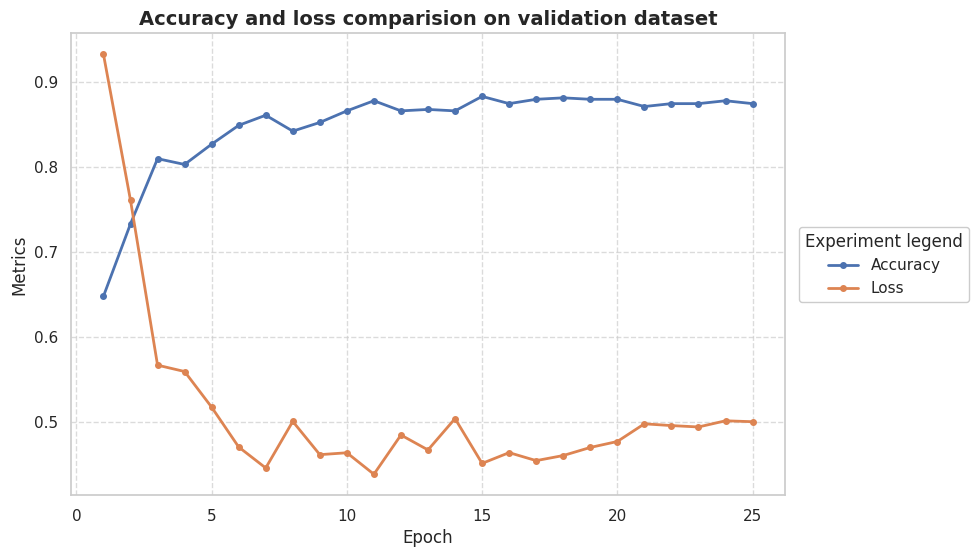

In [ ]:
plot_comparison(acc, loss, "Accuracy and loss comparision on validation dataset")

## Predykcja na zbiorze testowym

In [ ]:
print("Generowanie predykcji na zbiorze testowym...")
model.eval()
all_predictions = []

with torch.no_grad():
    for x, x_lens in test_loader:
        x = x.to(device)
        preds = model(x, x_lens)
        _, predicted_classes = torch.max(preds.data, 1)
        all_predictions.extend(predicted_classes.cpu().tolist())

# zapis do pliku
with open('pred.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    for pred in all_predictions:
        writer.writerow([pred])

print("Zapisano wyniki w 'pred.csv'.")

Generowanie predykcji na zbiorze testowym...
Zapisano wyniki w 'pred.csv'.
